# Задание 4.16

В области, ограниченной эллипсом $\left(\dfrac{u}{23}\right)^2+\left(\dfrac{v}{6}\right)^2=1$, случайным образом выбираются две точки. Пусть $A$ и $B$ — события, состоящие в том, что: $A$ — расстояние между выбранными точками меньше $9{,}2$; $B$ — координаты первой точки больше 0, а координаты второй точки меньше 0. Найдите приближённо, методом Монте-Карло: 1) вероятность $\mathbb P(A)$; 2) условную вероятность $\mathbb P(A\mid B)$. *Указание:* получите внутри заданного эллипса 100000 пар точек и, используя все эти пары точек, найдите ответы, округляя их до одного знака после запятой.

**Ответ:** 1) $\mathbb P(A)=0{,}35$; 2) $\mathbb P(A\mid B)=0{,}07$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Равномерная точка в эллипсе.** Отображение $(s,t)\mapsto(u,v)=(23s,\,6t)$ переводит единичный круг в эллипс и умножает все площади на одну и ту же константу $23\cdot6$. Поэтому равномерная точка круга переходит в равномерную точку эллипса. Равномерная точка круга: $s=\sqrt{U_1}\cos2\pi U_2$, $t=\sqrt{U_1}\sin2\pi U_2$. Другой способ — метод отбора: генерировать точки в прямоугольнике $[-23,23]\times[-6,6]$ и оставлять попавшие в эллипс (доля $\pi/4$).

**События.**
- $A=\{|P_1P_2|<9{,}2\}$;
- $B=\{u_1>0,\ v_1>0,\ u_2<0,\ v_2<0\}$ — первая точка в I четверти, вторая в III. По симметрии $\mathbb P(B)=\frac14\cdot\frac14=\frac1{16}$, т.е. в среднем $\approx6250$ пар из $100\,000$.

**Оценки Монте-Карло:**

$$
\mathbb P(A)\approx\frac{N(A)}{N},\qquad \mathbb P(A\mid B)\approx\frac{N(AB)}{N(B)} .
$$

При условии $B$ точки лежат в противоположных четвертях, поэтому расстояние обычно велико, и $\mathbb P(A\mid B)$ намного меньше $\mathbb P(A)$. Близкими могут оказаться только точки рядом с центром эллипса.

Точных формул здесь нет, поэтому для контрольной (красной) линии на графиках используем отдельную большую выборку ($N=4\cdot10^6$ пар).

Контроль (N = 4 000 000): P(A) ≈ 0.3510,  P(A|B) ≈ 0.0685,  P(B) ≈ 0.0625 (1/16 = 0.0625)
Монте-Карло (N = 100000): P(A) ≈ 0.3524 ≈ 0.35;  N(B) = 6280,  P(A|B) ≈ 0.0677 ≈ 0.07


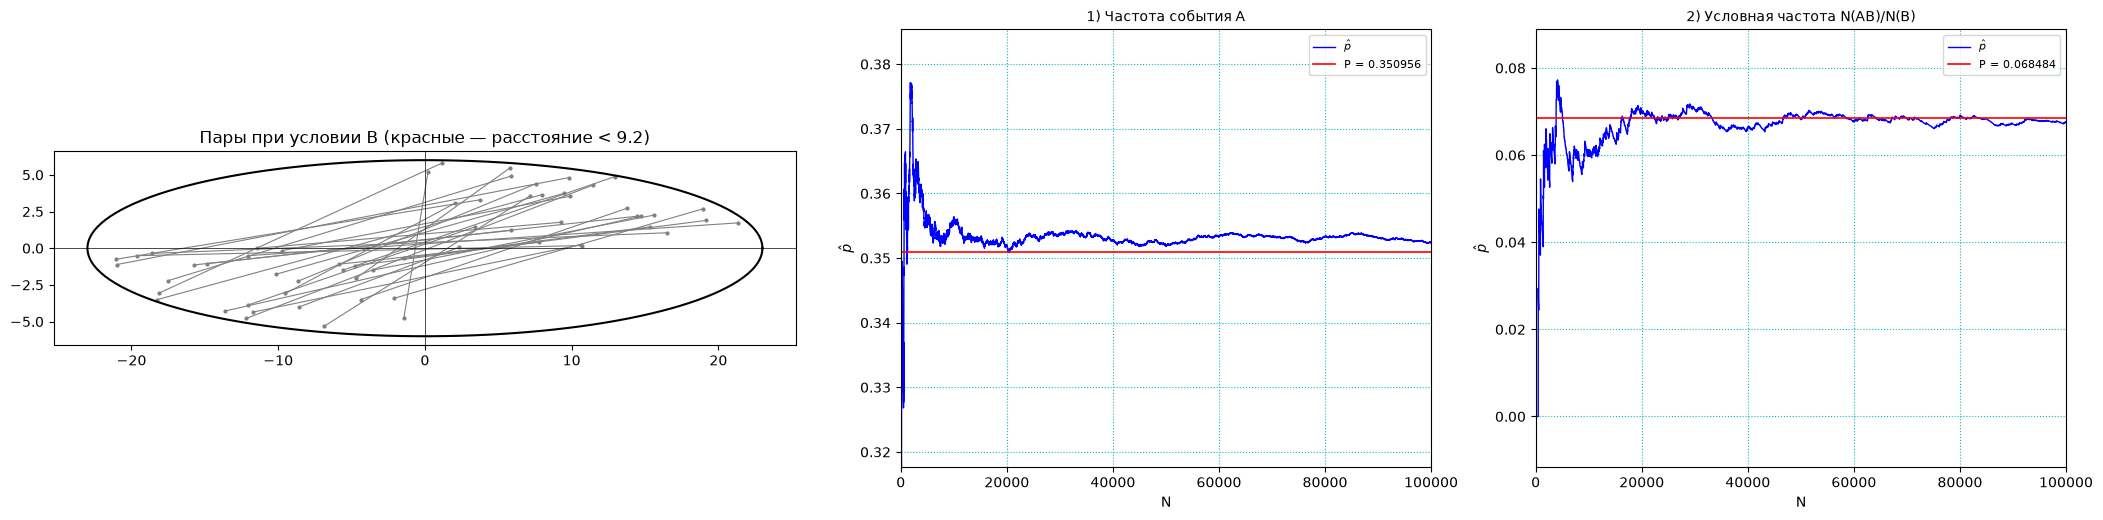

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


ea, eb, d = 23, 6, 9.2


def uniform_ellipse(n):
    """n точек, равномерно распределённых внутри эллипса (u/23)^2 + (v/6)^2 <= 1."""
    r = np.sqrt(rng.random(n))
    phi = 2*np.pi*rng.random(n)
    return ea*r*np.cos(phi), eb*r*np.sin(phi)


def experiment(n):
    """n пар точек: возвращает индикаторы событий A и B и сами точки."""
    u1, v1 = uniform_ellipse(n)
    u2, v2 = uniform_ellipse(n)
    A = np.hypot(u1 - u2, v1 - v2) < d                     # расстояние меньше 9.2
    B = (u1 > 0) & (v1 > 0) & (u2 < 0) & (v2 < 0)          # 1-я точка в I четверти, 2-я — в III
    return A, B, (u1, v1, u2, v2)


# ---------- Контрольная оценка по большой выборке ----------
A_ref, B_ref, _ = experiment(4_000_000)
PA_ref, PAB_ref = A_ref.mean(), (A_ref & B_ref).sum() / B_ref.sum()
print(f"Контроль (N = 4 000 000): P(A) ≈ {PA_ref:.4f},  P(A|B) ≈ {PAB_ref:.4f},  P(B) ≈ {B_ref.mean():.4f} (1/16 = {1/16})")

# ---------- Метод Монте-Карло: 100 000 пар точек ----------
N = 100_000
A, B, (u1, v1, u2, v2) = experiment(N)
PA, PAB = A.mean(), (A & B).sum() / B.sum()
print(f"Монте-Карло (N = {N}): P(A) ≈ {PA:.4f} ≈ {PA:.2f};  N(B) = {B.sum()},  P(A|B) ≈ {PAB:.4f} ≈ {PAB:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 5.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
t = np.linspace(0, 2*np.pi, 300)
idx = np.flatnonzero(B)[:30]                  # пары, для которых выполнено B
for i in idx:
    axes[0].plot([u1[i], u2[i]], [v1[i], v2[i]], "-o", ms=2, lw=0.8, color="red" if A[i] else "gray")
axes[0].plot(ea*np.cos(t), eb*np.sin(t), "k"); axes[0].axhline(0, color="k", lw=0.5); axes[0].axvline(0, color="k", lw=0.5)
axes[0].set_aspect("equal"); axes[0].set_title("Пары при условии B (красные — расстояние < 9.2)")
plot_freq(axes[1], A, PA_ref, "1) Частота события A")
plot_freq(axes[2], A, PAB_ref, "2) Условная частота N(AB)/N(B)", cond=B)
fig.tight_layout()
plt.show()